In [5]:
import requests
import json

weather_url = "https://api.open-meteo.com/v1/forecast"
weather_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "temperature_2m,relative_humidity_2m",
    "timezone": "Asia/Karachi",
}

r = requests.get(weather_url, params=weather_params)
print("Status:", r.status_code)

data = r.json()
print(data.keys())
print(json.dumps(data, indent=2)[:1500])


Status: 200
dict_keys(['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly'])
{
  "latitude": 31.528997,
  "longitude": 74.38995,
  "generationtime_ms": 0.04363059997558594,
  "utc_offset_seconds": 18000,
  "timezone": "Asia/Karachi",
  "timezone_abbreviation": "GMT+5",
  "elevation": 222.0,
  "hourly_units": {
    "time": "iso8601",
    "temperature_2m": "\u00b0C",
    "relative_humidity_2m": "%"
  },
  "hourly": {
    "time": [
      "2026-11-06T00:00",
      "2026-11-06T01:00",
      "2026-11-06T02:00",
      "2026-11-06T03:00",
      "2026-11-06T04:00",
      "2026-11-06T05:00",
      "2026-11-06T06:00",
      "2026-11-06T07:00",
      "2026-11-06T08:00",
      "2026-11-06T09:00",
      "2026-11-06T10:00",
      "2026-11-06T11:00",
      "2026-11-06T12:00",
      "2026-11-06T13:00",
      "2026-11-06T14:00",
      "2026-11-06T15:00",
      "2026-11-06T16:00",
      "2026-11-06T17:00",
      "2

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

df24 = hist.copy().dropna()

df24["hour"] = df24["time"].dt.hour
df24["aqi_lag1"] = df24["us_aqi"].shift(1)
df24["aqi_lag24"] = df24["us_aqi"].shift(24)   # kal isi waqt ka AQI
df24["target24"] = df24["us_aqi"].shift(-24)   # 24 ghante baad ka AQI

df24 = df24.dropna()

feats = ["hour", "pm2_5", "pm10", "aqi_lag1", "aqi_lag24"]
X = df24[feats]
y = df24["target24"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# baseline: "kal isi waqt jaisa AQI" ya "abhi jaisa"
print("Baseline (abhi jaisa) MAE:", mean_absolute_error(y_test, X_test["us_aqi"] if "us_aqi" in X_test else X_test["aqi_lag1"]))

lr = LinearRegression().fit(X_train, y_train)
print("Linear Regression MAE:", mean_absolute_error(y_test, lr.predict(X_test)))

Baseline (abhi jaisa) MAE: 23.89032258064516
Linear Regression MAE: 18.144489477615593


In [7]:
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 30,
    "timezone": "Asia/Karachi",
}
r = requests.get(url, params=params)
hist = pd.DataFrame(r.json()["hourly"])
hist["time"] = pd.to_datetime(hist["time"])
print(hist.shape)
print(hist.head())

(840, 4)
                 time  pm10  pm2_5  us_aqi
0 2026-10-07 00:00:00  59.4   44.7   136.0
1 2026-10-07 01:00:00  61.9   43.9   134.0
2 2026-10-07 02:00:00  68.5   44.4   132.0
3 2026-10-07 03:00:00  78.5   46.2   130.0
4 2026-10-07 04:00:00  82.4   44.9   129.0


In [8]:
import requests
import pandas as pd
import sqlite3

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 30,
    "timezone": "Asia/Karachi",
}
hist = pd.DataFrame(requests.get(url, params=params).json()["hourly"])
hist["time"] = pd.to_datetime(hist["time"])

conn = sqlite3.connect("aqi.db")
hist.to_sql("aqi_data", conn, if_exists="replace", index=False)

print(pd.read_sql("SELECT COUNT(*) AS rows FROM aqi_data", conn))

   rows
0   840


In [9]:
q = """
SELECT DATE(time) AS day, ROUND(AVG(us_aqi),1) AS avg_aqi, MAX(us_aqi) AS max_aqi
FROM aqi_data
GROUP BY DATE(time)
ORDER BY avg_aqi DESC
LIMIT 5
"""
print(pd.read_sql(q, conn))

          day  avg_aqi  max_aqi
0  2026-11-02    205.3    215.0
1  2026-11-03    202.6    214.0
2  2026-11-05    199.2    202.0
3  2026-11-04    195.5    201.0
4  2026-10-22    191.9    194.0


In [10]:
df = hist.copy()

# missing values hatao
df = df.dropna()

# naye columns (features)
df["hour"] = df["time"].dt.hour
df["aqi_lag1"] = df["us_aqi"].shift(1)      # pichle ghante ka AQI
df["pm25_lag1"] = df["pm2_5"].shift(1)      # pichle ghante ka PM2.5
df["target"] = df["us_aqi"].shift(-1)       # agle ghante ka AQI (jo predict karna hai)

df = df.dropna()
print(df.shape)
print(df.head())

(820, 8)
                 time  pm10  pm2_5  us_aqi  hour  aqi_lag1  pm25_lag1  target
1 2026-10-07 01:00:00  61.9   43.9   134.0     1     136.0       44.7   132.0
2 2026-10-07 02:00:00  68.5   44.4   132.0     2     134.0       43.9   130.0
3 2026-10-07 03:00:00  78.5   46.2   130.0     3     132.0       44.4   129.0
4 2026-10-07 04:00:00  82.4   44.9   129.0     4     130.0       46.2   127.0
5 2026-10-07 05:00:00  47.6   29.6   127.0     5     129.0       44.9   124.0


In [11]:
q = "SELECT COUNT(*) AS unhealthy_hours FROM aqi_data WHERE us_aqi > 150"
print(pd.read_sql(q, conn))

   unhealthy_hours
0              545


In [12]:
import joblib
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

rf_mae = mean_absolute_error(y_test, rf.predict(X_test))
lr_mae = mean_absolute_error(y_test, lr.predict(X_test))
print("Linear Regression MAE:", lr_mae)
print("Random Forest MAE:", rf_mae)

best = rf if rf_mae < lr_mae else lr
joblib.dump(best, "aqi_model_24h.pkl")
joblib.dump(feats, "features.pkl")
print("Saved model:", type(best).__name__)

Linear Regression MAE: 18.144489477615593
Random Forest MAE: 24.920129032258064
Saved model: LinearRegression


In [13]:
q = """
SELECT strftime('%H', time) AS hour, ROUND(AVG(us_aqi),1) AS avg_aqi
FROM aqi_data
GROUP BY hour
ORDER BY avg_aqi DESC
LIMIT 5
"""
print(pd.read_sql(q, conn))

  hour  avg_aqi
0   18    162.3
1   19    161.3
2   17    161.1
3   20    160.0
4   03    159.6


In [14]:
print("Baseline (abhi jaisa) MAE:", mean_absolute_error(y_test, X_test["aqi_lag1"]))
print("Baseline (kal isi waqt jaisa) MAE:", mean_absolute_error(y_test, X_test["aqi_lag24"]))

Baseline (abhi jaisa) MAE: 23.89032258064516
Baseline (kal isi waqt jaisa) MAE: 29.767741935483873


In [15]:
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "past_days": 30,
    "timezone": "Asia/Karachi",
}

r = requests.get(url, params=params)
print("Status:", r.status_code)

hist = pd.DataFrame(r.json()["hourly"])
hist["time"] = pd.to_datetime(hist["time"])
print(hist.shape)
print(hist.describe())


Status: 200
(840, 4)
                                time        pm10       pm2_5      us_aqi
count                            840  822.000000  822.000000  823.000000
mean   2026-10-24 11:30:00.000000256   91.667640   75.256204  159.236938
min              2026-10-07 00:00:00   10.500000    9.300000   80.000000
25%              2026-10-15 17:45:00   56.350000   44.625000  145.000000
50%              2026-10-24 11:30:00   85.300000   67.500000  162.000000
75%              2026-11-02 05:15:00  118.500000   99.150000  174.000000
max              2026-11-10 23:00:00  292.400000  197.000000  215.000000
std                              NaN   45.964857   39.043585   26.582809


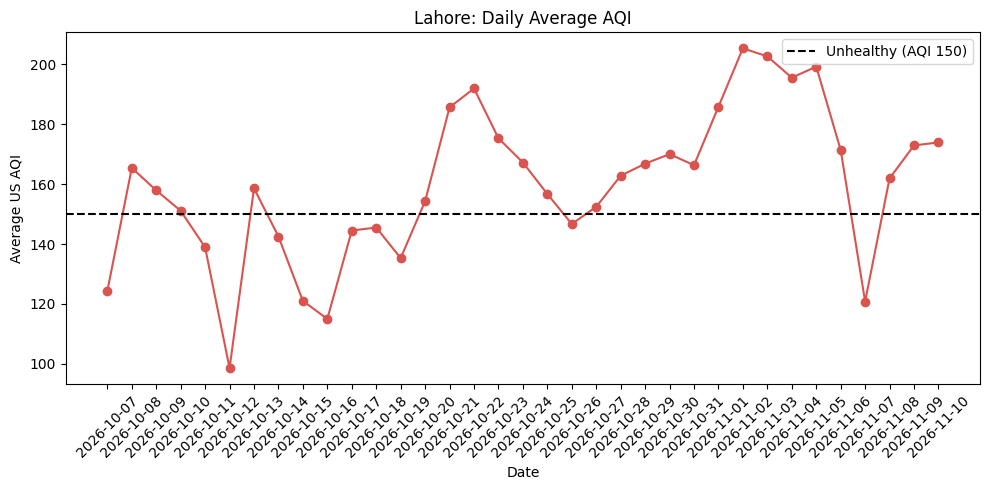

In [16]:
import matplotlib.pyplot as plt

q = """
SELECT DATE(time) AS day, ROUND(AVG(us_aqi),1) AS avg_aqi
FROM aqi_data
GROUP BY day
ORDER BY day
"""
d2 = pd.read_sql(q, conn)

plt.figure(figsize=(10, 5))
plt.plot(d2["day"], d2["avg_aqi"], marker="o", color="#d9534f")
plt.axhline(150, color="black", linestyle="--", label="Unhealthy (AQI 150)")
plt.title("Lahore: Daily Average AQI")
plt.xlabel("Date")
plt.ylabel("Average US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

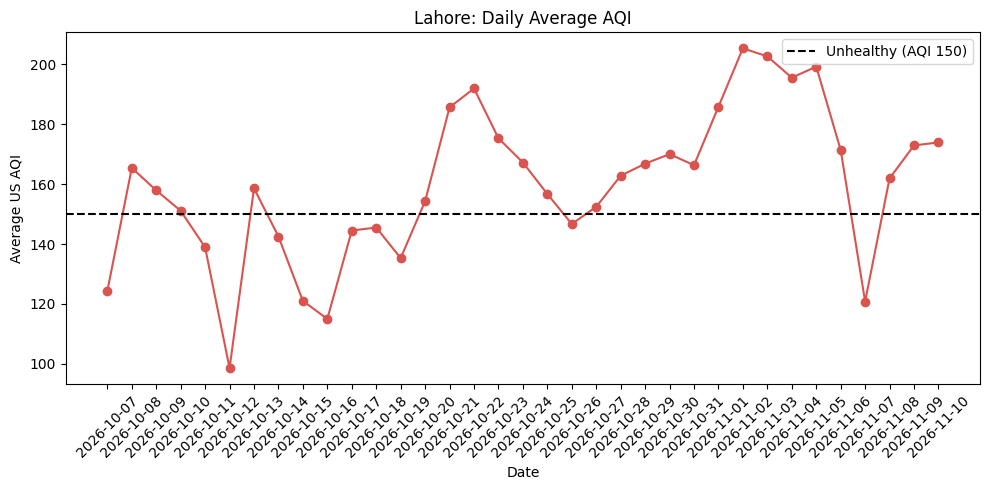

In [17]:
q = """
SELECT DATE(time) AS day, ROUND(AVG(us_aqi),1) AS avg_aqi
FROM aqi_data
GROUP BY day
ORDER BY day
"""
d2 = pd.read_sql(q, conn)

plt.figure(figsize=(10, 5))
plt.plot(d2["day"], d2["avg_aqi"], marker="o", color="#d9534f")
plt.axhline(150, color="black", linestyle="--", label="Unhealthy (AQI 150)")
plt.title("Lahore: Daily Average AQI")
plt.xlabel("Date")
plt.ylabel("Average US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

features = ["hour", "pm2_5", "pm10", "aqi_lag1", "pm25_lag1"]
X = df[features]
y = df["target"]

# time order mein baanto (shuffle nahi)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

model = LinearRegression()
model.fit(X_train, y_train)

pred = model.predict(X_test)
print("MAE:", mean_absolute_error(y_test, pred))

MAE: 2.3124368889489664


In [19]:
baseline_pred = X_test["aqi_lag1"]
print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))

Baseline MAE: 2.225609756097561


In [20]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)
print("Random Forest MAE:", mean_absolute_error(y_test, rf_pred))

Random Forest MAE: 3.2435365853658524


In [21]:
import pandas as pd

aq_url = "https://air-quality-api.open-meteo.com/v1/air-quality"
aq_params = {
    "latitude": 31.5497,
    "longitude": 74.3436,
    "hourly": "pm10,pm2_5,us_aqi",
    "timezone": "Asia/Karachi",
}

r = requests.get(aq_url, params=aq_params)
print("Status:", r.status_code)

aq = r.json()
aq_df = pd.DataFrame(aq["hourly"])
aq_df["time"] = pd.to_datetime(aq_df["time"])
print(aq_df.head())
print(aq_df.shape)

Status: 200
                 time   pm10  pm2_5  us_aqi
0 2026-11-06 00:00:00  120.6  116.2   191.0
1 2026-11-06 01:00:00  115.3  110.8   189.0
2 2026-11-06 02:00:00  108.3  104.1   188.0
3 2026-11-06 03:00:00  100.4   96.2   187.0
4 2026-11-06 04:00:00   93.8   89.9   186.0
(120, 4)


In [22]:
y_train_d = y_train - X_train["aqi_lag1"]

rf2 = RandomForestRegressor(n_estimators=100, random_state=42)
rf2.fit(X_train, y_train_d)

rf2_pred = rf2.predict(X_test) + X_test["aqi_lag1"]
print("RF (change) MAE:", mean_absolute_error(y_test, rf2_pred))

RF (change) MAE: 2.810243902439025


In [23]:
print(data["hourly"].keys())
print(data["hourly"]["time"][0])
print(data["hourly"]["temperature_2m"][0])


dict_keys(['time', 'temperature_2m', 'relative_humidity_2m'])
2026-11-06T00:00
20.7


In [24]:

print(data["hourly"]["time"][1])
print(data["hourly"]["temperature_2m"][1])
print(len(data["hourly"]["time"]))


2026-11-06T01:00
20.3
168


In [25]:
import pandas as pd

df = pd.DataFrame(data["hourly"])
print(df.head())
print(df.shape)


               time  temperature_2m  relative_humidity_2m
0  2026-11-06T00:00            20.7                    71
1  2026-11-06T01:00            20.3                    72
2  2026-11-06T02:00            20.0                    72
3  2026-11-06T03:00            19.9                    72
4  2026-11-06T04:00            19.6                    72
(168, 3)


In [26]:
df["time"] = pd.to_datetime(df["time"])
print(df.dtypes)
print(df["temperature_2m"].max(), df["temperature_2m"].min())

time                    datetime64[ns]
temperature_2m                 float64
relative_humidity_2m             int64
dtype: object
29.1 16.0


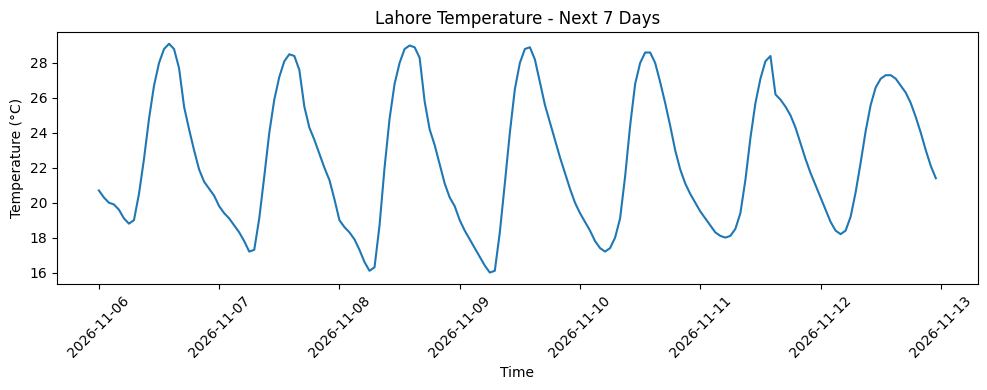

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(df["time"], df["temperature_2m"])
plt.title("Lahore Temperature - Next 7 Days")
plt.xlabel("Time")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

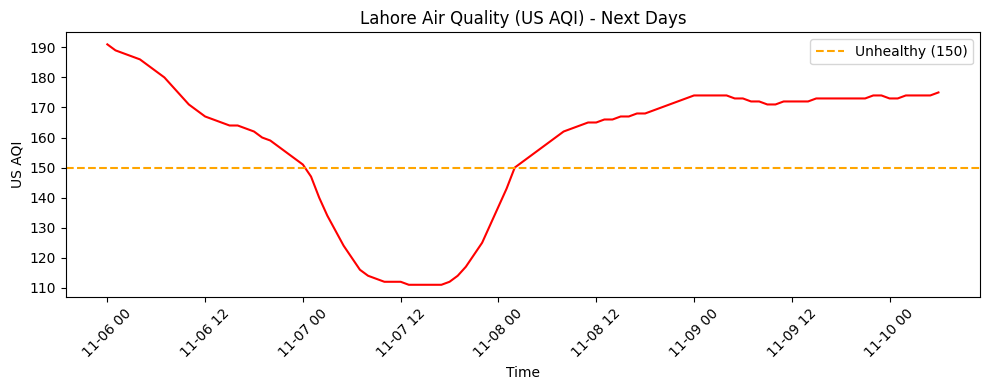

Max AQI: 191.0
Average AQI: 157.90291262135923


In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(aq_df["time"], aq_df["us_aqi"], color="red")
plt.axhline(150, color="orange", linestyle="--", label="Unhealthy (150)")
plt.title("Lahore Air Quality (US AQI) - Next Days")
plt.xlabel("Time")
plt.ylabel("US AQI")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

print("Max AQI:", aq_df["us_aqi"].max())
print("Average AQI:", aq_df["us_aqi"].mean())